# Netflix Global Top 10 Analysis

### Kailyn

This notebook examines the overlap between our sampled Korean dramas and Netflix's Global Top 10 dataset. We plan on using the Netflix data as a supplementary measure of overall drama viewership, rather than as a direct measure of OST popularity, to answer RQ1.

**Table of Contents**
1. [Loading and Inspecting the Data](#1)
2. [Normalizing Drama Titles](#2)
3. [Matching Dramas with Netflix Data](#3)
4. [Summarizing Netflix Viewership](#4)
5. [Visualizing Netflix Coverage and Viewership](#5)

**Important Notes**
- The Netflix dataset contains titles that reached the weekly Global Top 10, not every title available on Netflix.
- We restrict our analysis to the `TV (Non-English)` category to exclude films and other content categories.
- Netflix's `weekly_views` metric is not available for the entire historical period. Missing values must not be interpreted as zero.
- Netflix viewership measures overall drama engagement, not soundtrack popularity.

<a id=1></a>
## 1. Loading and Inspecting the Data

We load our final sample of 94 dramas and Netflix's historical Global Top 10
dataset.

The Netflix dataset contains weekly records for films and television titles
across English and non-English categories. Each record includes the title,
week, category, ranking, hours viewed, and (when available) estimated views.

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Load datasets
final_drama_set = pd.read_csv("../final_drama_set.csv")
netflix = pd.read_csv("../dataset3_netflix/all-weeks-global.tsv", sep="\t")

# Remove any accidental whitespace from column names
final_drama_set.columns = final_drama_set.columns.str.strip()
netflix.columns = netflix.columns.str.strip()

# Inspect column names
print("Drama dataset columns:")
print(final_drama_set.columns.tolist())

print("\nNetflix dataset columns:")
print(netflix.columns.tolist())

# Preview both datasets
display(final_drama_set.head())
display(netflix.head())

Drama dataset columns:
['show', 'group', 'show_page_found', 'show_page_status', 'ost_pages_attempted', 'ost_pages_found', 'ost_page_found', 'actors_attempted', 'actor_pages_found', 'actor_pages_missing', 'found_actors', 'missing_actors']

Netflix dataset columns:
['week', 'category', 'weekly_rank', 'show_title', 'season_title', 'weekly_hours_viewed', 'runtime', 'weekly_views', 'cumulative_weeks_in_top_10']


,show,group,show_page_found,show_page_status,ost_pages_attempted,ost_pages_found,ost_page_found,actors_attempted,actor_pages_found,actor_pages_missing,found_actors,missing_actors
0,Sound Candy (2023),music,True,cached,1,1,True,3,3,0,Choi Yoo Jung; JR; Baek Seo Hoo,NaN
1,Dream Knight (2015),music,True,cached,1,1,True,6,6,0,Song Ha Yoon; JB; Jr.; Choi Young Jae; Park Ji...,NaN
2,Entertainer (2016),music,True,cached,1,1,True,4,4,0,Ji Sung; Hye Ri; Chae Jung Ahn; Kang Min Hyuk,NaN
3,Spring of Youth (2025),music,True,cached,1,1,True,3,3,0,Ha Yoo Joon; Park Ji Hoo; Lee Seung Hyup,NaN
4,The Miracle (2016),music,True,cached,1,1,True,1,1,0,Hong Yoon Hwa,NaN


,week,category,weekly_rank,show_title,season_title,weekly_hours_viewed,runtime,weekly_views,cumulative_weeks_in_top_10
0,2026-11-15,Films (English),1,Heartland,NaN,13900000,1.9000,7300000.0,1
1,2026-11-15,Films (English),2,A Dog's Perfect Christmas,NaN,12200000,1.6833,7200000.0,2
2,2026-11-15,Films (English),3,The Gospel of Christmas,NaN,10700000,1.7500,6100000.0,1
3,2026-11-15,Films (English),4,Reminders of Him,NaN,8300000,1.9000,4400000.0,1
4,2026-11-15,Films (English),5,Allen,NaN,6200000,1.7833,3500000.0,1


In [28]:
# Inspect the Netflix dataset's categories and date range
print("Netflix categories:")
display(netflix["category"].value_counts())

print("\nDate range:")
print(netflix["week"].min(), "to", netflix["week"].max())

print("\nNumber of unique Netflix titles:")
print(netflix["show_title"].nunique())

print("\nNumber of dramas in our final sample:")
print(final_drama_set["show"].nunique())

Netflix categories:


category
Films (English)        2810
Films (Non-English)    2810
TV (English)           2810
TV (Non-English)       2810
Name: count, dtype: int64


Date range:
2021-07-04 to 2026-11-15

Number of unique Netflix titles:
3585

Number of dramas in our final sample:
94


<a id=2></a>
## 2. Normalizing Drama Titles

The two datasets do not always use identical title formatting. For example,
our drama dataset may include a release year in parentheses, while Netflix's
dataset may omit it.

To improve matching, we normalize titles by:
- Converting text to lowercase.
- Removing trailing release years.
- Removing punctuation.
- Standardizing whitespace.
- Applying Unicode normalization. (Suggested by GenAI, in case we had missed anything else)

This allows us to match titles despite minor formatting differences.

In [29]:
import re
import unicodedata

def normalize_title(title):
    """Standardize a drama title for matching across datasets."""
    if pd.isna(title):
        return ""

    # Normalize Unicode characters and convert to lowercase
    title = unicodedata.normalize("NFKC", str(title))
    title = title.lower().strip()

    # Remove a trailing release year, optionally enclosed in parentheses
    title = re.sub(r"\s*\(?\b(?:19|20)\d{2}\)?$", "", title)

    # Remove punctuation and standardize whitespace
    title = re.sub(r"[^\w\s]", "", title)
    title = re.sub(r"\s+", " ", title)

    return title.strip()


# Create normalized title columns
final_drama_set["normalized_title"] = (
    final_drama_set["show"].apply(normalize_title)
)

netflix["normalized_title"] = (
    netflix["show_title"].apply(normalize_title)
)

# Check for duplicate normalized titles in our drama sample
duplicate_titles = final_drama_set[
    final_drama_set["normalized_title"].duplicated(keep=False)
].sort_values("normalized_title")

print("Duplicate normalized titles in our drama sample:")
display(duplicate_titles[["show", "group", "normalized_title"]])

Duplicate normalized titles in our drama sample:


,show,group,normalized_title


<a id=3></a>
## 3. Matching Dramas with Netflix Data

We restrict the Netflix dataset to the `TV (Non-English)` category because
our sample consists of Korean television dramas. This excludes films and
other categories that should not be included in the comparison. From there, we match the normalized Netflix titles against the normalized titles in our final drama sample. Each matched title is joined with its corresponding drama group (music-centered or control).

In [30]:
# Keep only non-English television titles
netflix_tv = netflix[
    netflix["category"] == "TV (Non-English)"
].copy()

print("Netflix records before filtering:", len(netflix))
print("Netflix TV (Non-English) records:", len(netflix_tv))

# Keep the title and group information from our final drama sample
drama_lookup = final_drama_set[
    ["show", "group", "normalized_title"]
].drop_duplicates()

# Match Netflix records to our drama sample
netflix_matched = netflix_tv.merge(
    drama_lookup,
    on="normalized_title",
    how="inner",
    validate="many_to_one"
)

# List unique matched dramas, including their group
matched_drama_list = (
    netflix_matched[
        ["show", "group", "normalized_title"]
    ]
    .drop_duplicates()
    .sort_values(["group", "show"])
    .reset_index(drop=True)
)

print("Number of matched dramas:", len(matched_drama_list))
display(matched_drama_list)

Netflix records before filtering: 11240
Netflix TV (Non-English) records: 2810
Number of matched dramas: 11


,show,group,normalized_title
0,A Time Called You (2023),control,a time called you
1,A Virtuous Business (2024),control,a virtuous business
2,Dear Hongrang (2025),control,dear hongrang
3,Hometown Cha-Cha-Cha (2021),control,hometown chachacha
4,Romance in the House (2024),control,romance in the house
5,Taxi Driver (2021),control,taxi driver
6,The Good Bad Mother (2023),control,the good bad mother
7,The Whirlwind (2024),control,the whirlwind
8,Castaway Diva (2023),music,castaway diva
9,Divorce Attorney Shin (2023),music,divorce attorney shin


In [31]:
# Summarize Netflix coverage by drama group
coverage = (
    final_drama_set.groupby("group")["normalized_title"]
    .apply(lambda titles: titles.isin(
        matched_drama_list["normalized_title"]
    ).sum())
    .to_frame("matched")
)

coverage["total"] = final_drama_set.groupby("group").size()
coverage["not_matched"] = coverage["total"] - coverage["matched"]

display(coverage)

,matched,total,not_matched
group,,,
control,8,47,39
music,3,47,44


<a id=4></a>
## 4. Summarizing Netflix Viewership

The Netflix dataset provides weekly observations rather than one record per
drama, so I aggregated these observations to obtain one summary row per matched drama.

We calculate:
- **Weeks in Top 10:** Number of distinct weeks the drama appeared.
- **Total weekly hours viewed:** Sum of its recorded weekly hours viewed.
- **Total weekly views:** Sum of its recorded weekly views, when available.
- **Best rank:** Highest placement in the weekly Top 10.
- **Cumulative weeks in Top 10:** Maximum reported cumulative number of
  appearances.

**Note**: A limitation of the dataset is that Netflix introduced its weekly views metric in June 2023. Earlier records have missing values for both
`weekly_views` and `runtime`, even when hours viewed are available. As a result, I have chosen to preserve missing values when calculating total views. A drama with no recorded weekly view counts should have a missing total, not a total of zero.

In [32]:
# Count how many weekly records have an actual view count
netflix_summary = (
    netflix_matched.groupby(
        ["show", "group", "normalized_title"]
    )
    .agg(
        weeks_in_top10=("week", "nunique"),

        # Hours viewed are available for the historical dataset
        total_weekly_hours=("weekly_hours_viewed", "sum"),

        # min_count=1 prevents an all-missing group from becoming zero
        total_weekly_views=(
            "weekly_views",
            lambda values: values.sum(min_count=1)
        ),

        # Number of weekly records with a reported view count
        weeks_with_view_data=("weekly_views", "count"),

        best_rank=("weekly_rank", "min"),
        cumulative_weeks=("cumulative_weeks_in_top_10", "max")
    )
    .reset_index()
)

print("Number of matched dramas:", len(netflix_summary))
display(
    netflix_summary.sort_values(
        ["group", "show"]
    )
)

Number of matched dramas: 11


,show,group,normalized_title,weeks_in_top10,total_weekly_hours,total_weekly_views,weeks_with_view_data,best_rank,cumulative_weeks
0,A Time Called You (2023),control,a time called you,4,85700000,7000000.0,4,4,4
1,A Virtuous Business (2024),control,a virtuous business,3,27000000,4200000.0,3,5,3
3,Dear Hongrang (2025),control,dear hongrang,3,79900000,7200000.0,3,3,3
6,Hometown Cha-Cha-Cha (2021),control,hometown chachacha,16,300580000,NaN,0,2,16
7,Romance in the House (2024),control,romance in the house,7,75900000,10500000.0,7,1,7
8,Taxi Driver (2021),control,taxi driver,1,5000000,1100000.0,1,9,1
9,The Good Bad Mother (2023),control,the good bad mother,7,122850000,1200000.0,1,3,7
10,The Whirlwind (2024),control,the whirlwind,1,16200000,1800000.0,1,4,1
2,Castaway Diva (2023),music,castaway diva,6,85400000,9700000.0,6,5,6
4,Divorce Attorney Shin (2023),music,divorce attorney shin,3,27190000,NaN,0,4,3


In [33]:
# Inspect dramas with missing or zero total weekly views
print("Dramas with missing total weekly views:")
display(
    netflix_summary[
        netflix_summary["total_weekly_views"].isna()
    ][
        ["show", "group", "weeks_in_top10", "weeks_with_view_data"]
    ]
)

print("Dramas with an actual total of zero weekly views:")
display(
    netflix_summary[
        netflix_summary["total_weekly_views"].eq(0)
    ][
        ["show", "group", "weeks_in_top10", "weeks_with_view_data"]
    ]
)

Dramas with missing total weekly views:


,show,group,weeks_in_top10,weeks_with_view_data
4,Divorce Attorney Shin (2023),music,3,0
6,Hometown Cha-Cha-Cha (2021),control,16,0


Dramas with an actual total of zero weekly views:


,show,group,weeks_in_top10,weeks_with_view_data


In [34]:
# Inspect the original weekly records for dramas with missing view totals
missing_view_titles = netflix_summary.loc[
    netflix_summary["total_weekly_views"].isna(),
    "normalized_title"
]

missing_view_records = netflix_matched[
    netflix_matched["normalized_title"].isin(missing_view_titles)
][
    [
        "show",
        "group",
        "week",
        "category",
        "weekly_hours_viewed",
        "runtime",
        "weekly_views"
    ]
].sort_values(["show", "week"])

display(missing_view_records)

,show,group,week,category,weekly_hours_viewed,runtime,weekly_views
37,Divorce Attorney Shin (2023),music,2023-04-02,TV (Non-English),7540000,NaN,NaN
36,Divorce Attorney Shin (2023),music,2023-04-09,TV (Non-English),9260000,NaN,NaN
35,Divorce Attorney Shin (2023),music,2023-04-16,TV (Non-English),10390000,NaN,NaN
53,Hometown Cha-Cha-Cha (2021),control,2021-09-05,TV (Non-English),9630000,NaN,NaN
52,Hometown Cha-Cha-Cha (2021),control,2021-09-12,TV (Non-English),14870000,NaN,NaN
51,Hometown Cha-Cha-Cha (2021),control,2021-09-19,TV (Non-English),18580000,NaN,NaN
50,Hometown Cha-Cha-Cha (2021),control,2021-09-26,TV (Non-English),23360000,NaN,NaN
49,Hometown Cha-Cha-Cha (2021),control,2021-10-03,TV (Non-English),28330000,NaN,NaN
48,Hometown Cha-Cha-Cha (2021),control,2021-10-10,TV (Non-English),32890000,NaN,NaN
47,Hometown Cha-Cha-Cha (2021),control,2021-10-17,TV (Non-English),37740000,NaN,NaN


<a id=5></a>
## 5. Visualizing Netflix Coverage and Viewership

Below, I have added the following visualizations to provide a brief overview of how the sampled dramas appear in Netflix's Global Top 10 dataset. I expect to either expand this notebook or make a new notebook as an extension in Milestone 5.

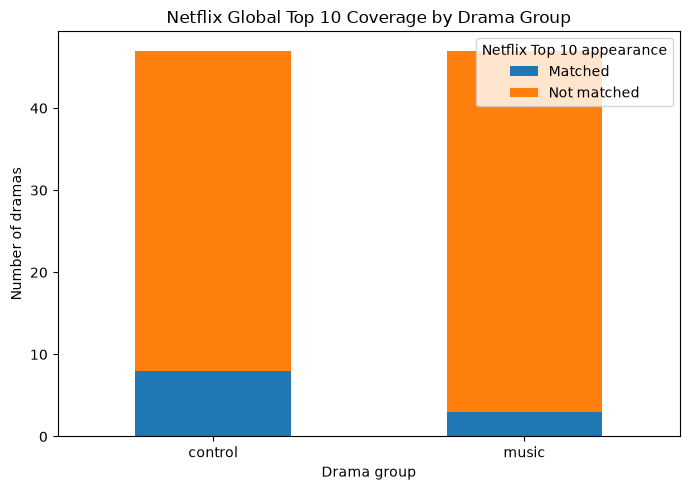

In [35]:
# Calculate matched and unmatched counts for each group
coverage = (
    final_drama_set.groupby("group")["normalized_title"]
    .apply(lambda titles: titles.isin(
        matched_drama_list["normalized_title"]
    ).sum())
    .to_frame("Matched")
)

coverage["Not matched"] = (
    final_drama_set.groupby("group").size() - coverage["Matched"]
)

# Plot coverage
coverage.plot(
    kind="bar",
    stacked=True,
    figsize=(7, 5)
)

plt.title("Netflix Global Top 10 Coverage by Drama Group")
plt.xlabel("Drama group")
plt.ylabel("Number of dramas")
plt.xticks(rotation=0)
plt.legend(title="Netflix Top 10 appearance")
plt.tight_layout()
plt.show()

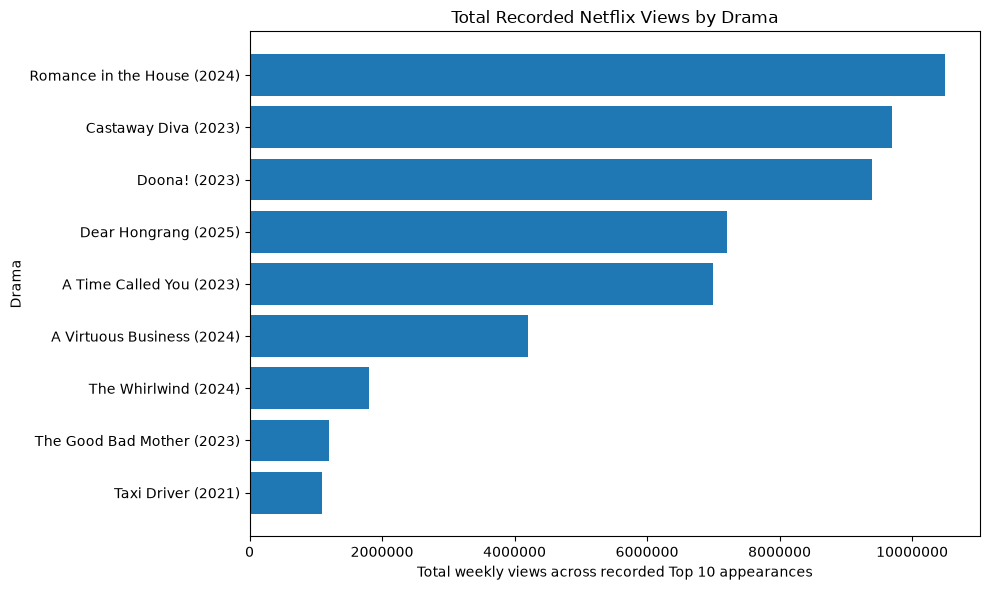

In [36]:
# Exclude dramas without any recorded weekly view counts
plot_data = netflix_summary.dropna(
    subset=["total_weekly_views"]
).sort_values("total_weekly_views", ascending=True)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["show"],
    plot_data["total_weekly_views"]
)

plt.title("Total Recorded Netflix Views by Drama")
plt.xlabel("Total weekly views across recorded Top 10 appearances")
plt.ylabel("Drama")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

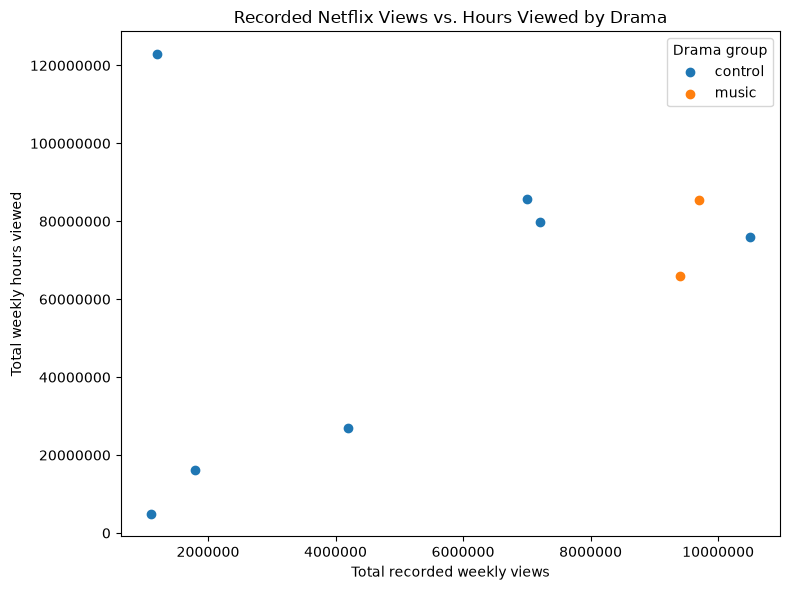

In [37]:
# Keep only records with both metrics available
plot_data = netflix_summary.dropna(
    subset=["total_weekly_views", "total_weekly_hours"]
)

plt.figure(figsize=(8, 6))

for group, data in plot_data.groupby("group"):
    plt.scatter(
        data["total_weekly_views"],
        data["total_weekly_hours"],
        label=group
    )

plt.title("Recorded Netflix Views vs. Hours Viewed by Drama")
plt.xlabel("Total recorded weekly views")
plt.ylabel("Total weekly hours viewed")
plt.ticklabel_format(style="plain", axis="both")
plt.legend(title="Drama group")
plt.tight_layout()
plt.show()